# Making the Invisible Roll Visible — analysis notebook

Every number, table and figure in the paper comes from `data/gbn_stats.json`, which holds **booth-level
aggregates** of the three Gautam Buddh Nagar rolls (61 Noida, 62 Dadri, 63 Jewar) pulled from the
dashboard database by the scripts in `analysis/` (`gbn_stats*.cjs`, `under18.cjs`, `deleted_stats.cjs`).
No row-level personal data is read here.

Sections:
1. Load the aggregates and print the headline numbers
2. The figures, cell by cell (same code as `make_figs.py`)
3. Under-18 check
4. Duplicate EPICs, the DELETED stamp and post-draft deletions
5. CPU scaling benchmark (Table 4b)
6. Rebuild the paper


## 1. Load the aggregates

In [1]:
"""Figures for the paper. Reads only data/gbn_stats.json (booth-level aggregates of the three
Gautam Buddh Nagar rolls) and the benchmark numbers printed by `node dist/cli.js ocr-eval` and
`translit-eval`, which are copied into the same file. No row-level data is touched.
Run from the paper/ folder:  python3 make_figs.py
"""
import json, collections
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
from PIL import Image

OUT = "figures/"
import os; os.makedirs(OUT, exist_ok=True)
ST = json.load(open("data/gbn_stats.json"))
ACS = ST["acs"]; ORDER = ["61", "62", "63"]
JW = ST["jewarRun"]
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
AC_COL = {"61": BLUE, "62": ORANGE, "63": AQUA}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 220, "legend.frameon": False,
})
sizes = json.load(open(OUT + "sizes.json")) if __import__("os").path.exists(OUT + "sizes.json") else {}

def save(name):
    plt.tight_layout(); plt.savefig(OUT + name, bbox_inches="tight"); plt.show()
    with Image.open(OUT + name) as im: sizes[name] = list(im.size)

def label(ac): return f"{ac} {ACS[ac]['name']}"

In [2]:
import pandas as pd
D = ST["district"]; P = ST["press"]
print("District rows", f"{D['rows']:,}", "parts", D["parts"], "sex ratio", D["sexRatio"], "added", f"{D['added']:,}", "modified", f"{D['modified']:,}")
rows = []
for ac in ORDER:
    a = ACS[ac]
    rows.append({"AC": label(ac), "rows": a["rows"], "parts": a["parts"], "pages": a["pages"], "sex ratio": a["sexRatio"],
                 "added": a["action"].get("added", 0), "modified": a["action"].get("modified", 0),
                 "median age": a["medianAge"]["all"], "18-19": a["age18_19"], "80+": a["age80plus"],
                 "dup EPICs": a["dupEpics"], "legacy EPIC rows": a["epicPat"].get("slash", 0)})
pd.DataFrame(rows).set_index("AC")

District rows 1,507,822 parts 2024 sex ratio 828 added 94,099 modified 11,221


,rows,parts,pages,sex ratio,added,modified,median age,18-19,80+,dup EPICs,legacy EPIC rows
AC,,,,,,,,,,,
61 Noida,589410,811,23371,810,29690,4460,42,4592,8593,2174,30
62 Dadri,605115,794,23728,844,44447,5013,41,6455,6447,2505,50798
63 Jewar,313297,419,12175,833,19962,1748,40,4478,4863,228,47434


## 2. Figures

Each cell is one figure of the paper; the PNG is also written to `figures/`.

### Fig 2: pipeline diagram

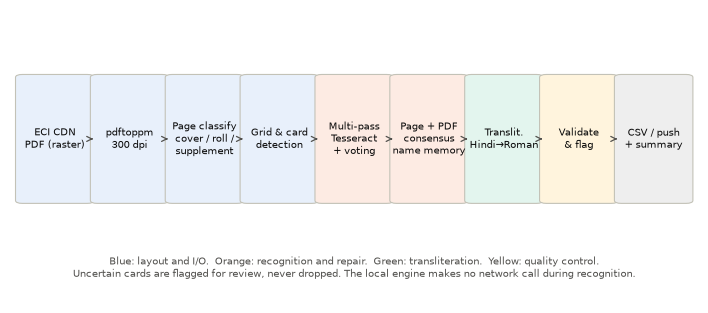

In [3]:
# ---------- Fig 2: pipeline diagram ----------
fig, ax = plt.subplots(figsize=(7.2, 3.2)); ax.axis("off"); ax.grid(False)
steps = [("ECI CDN\nPDF (raster)", "#e8f0fb"), ("pdftoppm\n300 dpi", "#e8f0fb"),
         ("Page classify\ncover / roll /\nsupplement", "#e8f0fb"), ("Grid & card\ndetection", "#e8f0fb"),
         ("Multi-pass\nTesseract\n+ voting", "#fdebe3"), ("Page + PDF\nconsensus\nname memory", "#fdebe3"),
         ("Translit.\nHindi→Roman", "#e3f5ee"), ("Validate\n& flag", "#fff4dd"), ("CSV / push\n+ summary", "#eeeeee")]
n = len(steps); xs = np.linspace(0.065, 0.935, n)
for (t, c), x in zip(steps, xs):
    ax.add_patch(FancyBboxPatch((x - 0.047, 0.35), 0.094, 0.42, boxstyle="round,pad=0.01", fc=c, ec=AXIS, lw=0.8, transform=ax.transAxes))
    ax.text(x, 0.56, t, ha="center", va="center", fontsize=7.2, color=INK, transform=ax.transAxes)
for a, b in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(b - 0.049, 0.56), xytext=(a + 0.049, 0.56), xycoords="axes fraction", arrowprops=dict(arrowstyle="->", color=INK2, lw=0.9))
ax.text(0.5, 0.12, "Blue: layout and I/O.  Orange: recognition and repair.  Green: transliteration.  Yellow: quality control.\n"
        "Uncertain cards are flagged for review, never dropped. The local engine makes no network call during recognition.",
        ha="center", va="center", fontsize=7.2, color=INK2, transform=ax.transAxes)
save("fig2_pipeline.png")

### Fig 3: accuracy vs baseline (hand-checked Dadri page, n = 30)

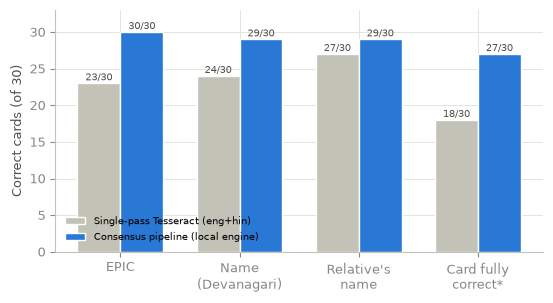

In [4]:
# ---------- Fig 3: accuracy vs baseline (hand-checked Dadri page, n = 30) ----------
B = ST["benchmark"]
fields = ["EPIC", "Name\n(Devanagari)", "Relative's\nname", "Card fully\ncorrect*"]
base = [B["baseline"]["epic"], B["baseline"]["name"], B["baseline"]["relName"], B["baseline"]["card"]]
full = [B["epic"], B["name"], B["relName"], B["fullyCorrect"]]
x = np.arange(len(fields)); w = 0.36
fig, ax = plt.subplots(figsize=(5.6, 3.1))
b1 = ax.bar(x - w / 2, base, w, color=AXIS, edgecolor="white", label="Single-pass Tesseract (eng+hin)")
b2 = ax.bar(x + w / 2, full, w, color=BLUE, edgecolor="white", label="Consensus pipeline (local engine)")
for r in list(b1) + list(b2):
    ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.4, f"{int(r.get_height())}/30", ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(fields); ax.set_ylim(0, 33); ax.set_ylabel("Correct cards (of 30)")
ax.legend(loc="lower left", fontsize=7.5)
save("fig3_accuracy_vs_baseline.png")

### Fig 4: flag calibration on the same page

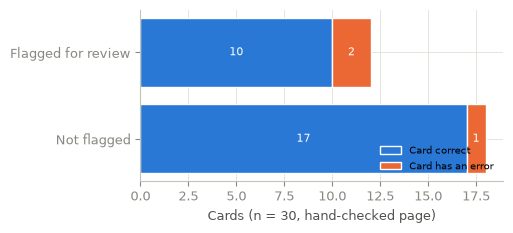

In [5]:
# ---------- Fig 4: flag calibration on the same page ----------
fig, ax = plt.subplots(figsize=(5.2, 2.4))
cats = ["Not flagged", "Flagged for review"]
nf = B["cards"] - B["flagged"]; wrong = [B["wrongUnflagged"], B["wrongFlagged"]]; correct = [nf - wrong[0], B["flagged"] - wrong[1]]
ax.barh(cats, correct, color=BLUE, edgecolor="white", label="Card correct")
ax.barh(cats, wrong, left=correct, color=ORANGE, edgecolor="white", label="Card has an error")
for i, (c, w_) in enumerate(zip(correct, wrong)):
    ax.text(c / 2, i, f"{c}", ha="center", va="center", color="white", fontsize=8)
    ax.text(c + w_ / 2, i, f"{w_}", ha="center", va="center", color="white", fontsize=8)
ax.set_xlabel("Cards (n = 30, hand-checked page)"); ax.legend(fontsize=7.5, loc="lower right")
save("fig4_flag_calibration.png")

### Fig 5: transliteration ablation

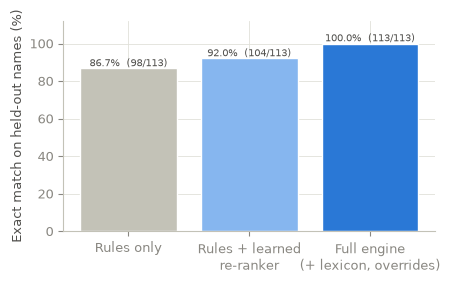

In [6]:
# ---------- Fig 5: transliteration ablation ----------
TR = ST["translit"]
fig, ax = plt.subplots(figsize=(4.6, 2.8))
labels = ["Rules only", "Rules + learned\nre-ranker", "Full engine\n(+ lexicon, overrides)"]
ks = [TR["rules"], TR["model"], TR["full"]]; vals = [100 * k / TR["n"] for k in ks]
b = ax.bar(np.arange(3), vals, color=[AXIS, "#86b6ef", BLUE], edgecolor="white")
for r, v, k in zip(b, vals, ks):
    ax.text(r.get_x() + r.get_width() / 2, v + 1.2, f"{v:.1f}%  ({k}/{TR['n']})", ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_ylim(0, 112); ax.set_ylabel("Exact match on held-out names (%)")
save("fig5_translit_ablation.png")

### Fig 6: electors per part

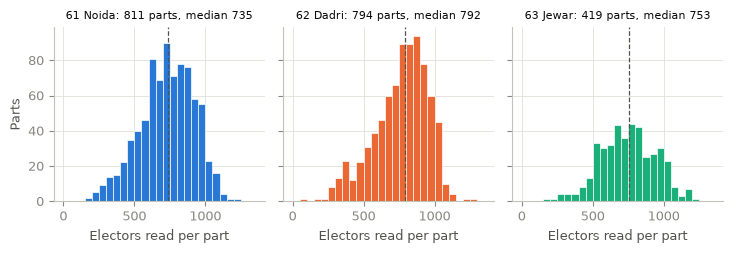

In [7]:
# ---------- Fig 6: electors per part ----------
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.6), sharey=True)
for ax, ac in zip(axes, ORDER):
    ns = [p["n"] for p in ACS[ac]["perPart"]]
    ax.hist(ns, bins=np.arange(0, 1400, 50), color=AC_COL[ac], edgecolor="white", linewidth=0.5)
    ax.axvline(np.median(ns), color=INK2, lw=0.9, ls="--")
    ax.set_title(f"{label(ac)}: {len(ns)} parts, median {int(np.median(ns))}", fontsize=8, color=INK)
    ax.set_xlabel("Electors read per part")
axes[0].set_ylabel("Parts")
save("fig6_part_size.png")

### Fig 7: completeness, rows read vs highest printed serial

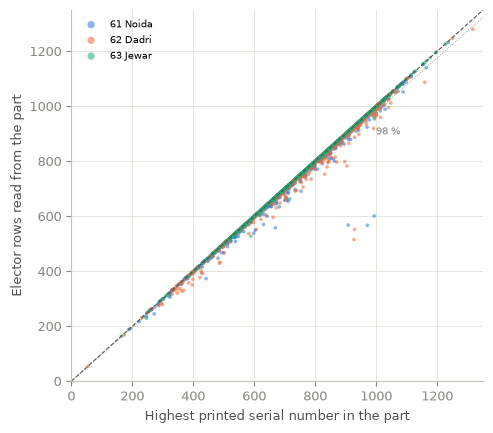

In [8]:
# ---------- Fig 7: completeness, rows read vs highest printed serial ----------
fig, ax = plt.subplots(figsize=(5.0, 4.4))
for ac in ORDER:
    pp = ACS[ac]["perPart"]
    ax.scatter([p["maxSerial"] for p in pp], [p["n"] for p in pp], s=7, alpha=0.55, color=AC_COL[ac], edgecolors="none", label=label(ac))
lim = 1350
ax.plot([0, lim], [0, lim], color=INK2, lw=0.8, ls="--"); ax.plot([0, lim], [0, 0.98 * lim], color=MUTED, lw=0.6, ls=":")
ax.text(lim * 0.74, lim * 0.665, "98 %", fontsize=7, color=MUTED)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel("Highest printed serial number in the part"); ax.set_ylabel("Elector rows read from the part")
ax.legend(fontsize=7.5, loc="upper left", markerscale=2)
save("fig7_completeness.png")

### Fig 8: flags on the Jewar run

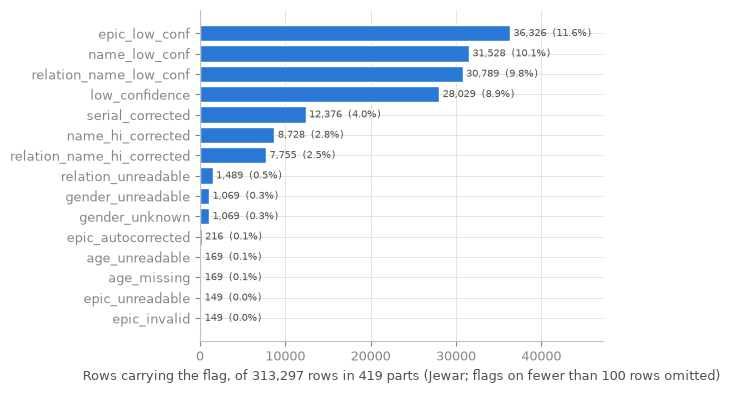

In [9]:
# ---------- Fig 8: flags on the Jewar run ----------
fc = sorted(JW["flagCounts"].items(), key=lambda kv: kv[1])
fc = [kv for kv in fc if kv[1] >= 100]
fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.barh([k for k, _ in fc], [v for _, v in fc], color=BLUE, edgecolor="white")
for i, (k, v) in enumerate(fc):
    ax.text(v + 400, i, f"{v:,}  ({100*v/JW['rows']:.1f}%)", va="center", fontsize=7, color=INK2)
ax.set_xlim(0, max(v for _, v in fc) * 1.3)
ax.set_xlabel(f"Rows carrying the flag, of {JW['rows']:,} rows in 419 parts (Jewar; flags on fewer than 100 rows omitted)")
save("fig8_jewar_flags.png")

### Fig 9: age–sex structure of the roll and of the additions

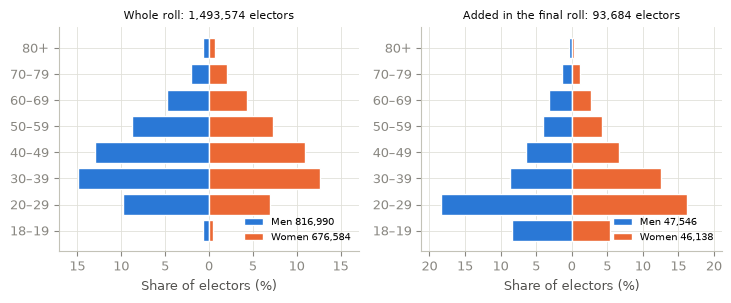

In [10]:
# ---------- Fig 9: age–sex structure of the roll and of the additions ----------
lab = ACS["61"]["pyramid"]["labels"]
M = np.sum([ACS[ac]["pyramid"]["M"] for ac in ORDER], axis=0); F = np.sum([ACS[ac]["pyramid"]["F"] for ac in ORDER], axis=0)
Ma = np.sum([ACS[ac]["addedPyramid"]["M"] for ac in ORDER], axis=0); Fa = np.sum([ACS[ac]["addedPyramid"]["F"] for ac in ORDER], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.1))
for ax, (m, f, title) in zip(axes, [(M, F, f"Whole roll: {M.sum()+F.sum():,} electors"), (Ma, Fa, f"Added in the final roll: {Ma.sum()+Fa.sum():,} electors")]):
    pm = 100 * m / (m.sum() + f.sum()); pf = 100 * f / (m.sum() + f.sum())
    ax.barh(lab, -pm, color=BLUE, edgecolor="white", label=f"Men {m.sum():,}")
    ax.barh(lab, pf, color=ORANGE, edgecolor="white", label=f"Women {f.sum():,}")
    mx = max(pm.max(), pf.max()) * 1.15; ax.set_xlim(-mx, mx)
    t = np.arange(0, mx, 5); tk = np.concatenate([-t[::-1][:-1], t]); ax.set_xticks(tk); ax.set_xticklabels([f"{int(abs(v))}" for v in tk])
    ax.set_xlabel("Share of electors (%)"); ax.set_title(title, fontsize=8, color=INK); ax.legend(fontsize=7, loc="lower right")
save("fig9_age_pyramids.png")

### Fig 10: single-year ages (age heaping)

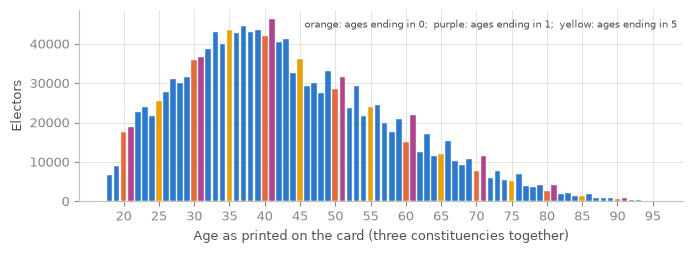

In [11]:
# ---------- Fig 10: single-year ages (age heaping) ----------
hist = collections.Counter()
for ac in ORDER:
    for k, v in ACS[ac]["ageHist"].items(): hist[int(k)] += v
ages = np.arange(18, 96); cnt = np.array([hist.get(int(a), 0) for a in ages])
fig, ax = plt.subplots(figsize=(7.0, 2.6))
MAG = "#b4418e"
cols = [ORANGE if a % 10 == 0 else (MAG if a % 10 == 1 else (YELLOW if a % 5 == 0 else BLUE)) for a in ages]
ax.bar(ages, cnt, color=cols, edgecolor="white", linewidth=0.3)
ax.set_xticks(np.arange(20, 96, 5))
ax.set_xlabel("Age as printed on the card (three constituencies together)"); ax.set_ylabel("Electors")
ax.text(0.99, 0.95, "orange: ages ending in 0;  purple: ages ending in 1;  yellow: ages ending in 5", transform=ax.transAxes, ha="right", va="top", fontsize=7, color=INK2)
save("fig10_age_heaping.png")

### Fig 11: booth-level distributions

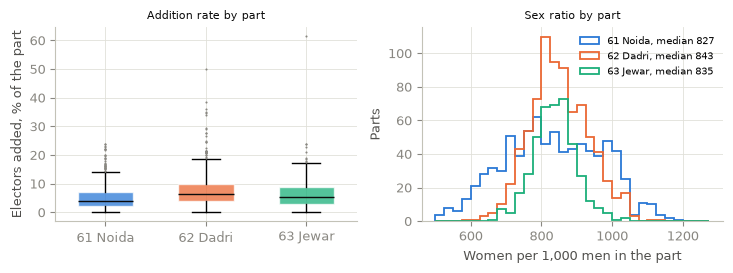

In [12]:
# ---------- Fig 11: booth-level distributions ----------
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.8))
ax = axes[0]
data = [[100 * p["added"] / p["n"] for p in ACS[ac]["addedByPart"] if p["n"] > 0] for ac in ORDER]
bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=True,
                flierprops=dict(marker=".", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"), medianprops=dict(color=INK))
ax.set_xticks([1, 2, 3]); ax.set_xticklabels([label(ac) for ac in ORDER])
for patch, ac in zip(bp["boxes"], ORDER): patch.set_facecolor(AC_COL[ac]); patch.set_alpha(0.75); patch.set_edgecolor("white")
ax.set_ylabel("Electors added, % of the part"); ax.set_title("Addition rate by part", fontsize=8, color=INK)
ax = axes[1]
for ac in ORDER:
    pp = ACS[ac]["perPart"]
    sr = [1000 * p["f"] / p["m"] for p in pp if p["m"] > 50 and p["f"] > 0]
    ax.hist(sr, bins=np.arange(500, 1300, 25), histtype="step", lw=1.3, color=AC_COL[ac], label=f"{label(ac)}, median {int(np.median(sr))}")
ax.set_xlabel("Women per 1,000 men in the part"); ax.set_ylabel("Parts"); ax.set_title("Sex ratio by part", fontsize=8, color=INK); ax.legend(fontsize=7)
save("fig11_booth_distributions.png")

### Fig 12: house-number sharing

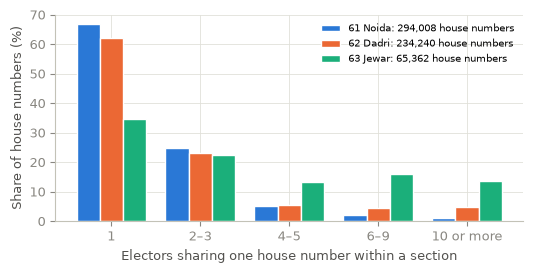

In [13]:
# ---------- Fig 12: house-number sharing ----------
bands = ["1", "2-3", "4-5", "6-9", "10+"]
fig, ax = plt.subplots(figsize=(5.4, 2.8))
w = 0.26; x = np.arange(len(bands))
for i, ac in enumerate(ORDER):
    hs = ACS[ac]["hhSize"]; tot = sum(hs.values())
    ax.bar(x + (i - 1) * w, [100 * hs[b] / tot for b in bands], w, color=AC_COL[ac], edgecolor="white", label=f"{label(ac)}: {tot:,} house numbers")
ax.set_xticks(x); ax.set_xticklabels(["1", "2–3", "4–5", "6–9", "10 or more"]); ax.set_xlabel("Electors sharing one house number within a section")
ax.set_ylabel("Share of house numbers (%)"); ax.legend(fontsize=7)
save("fig12_household_size.png")

### Fig 13: throughput vs pages in flight (CPU scaling benchmark)

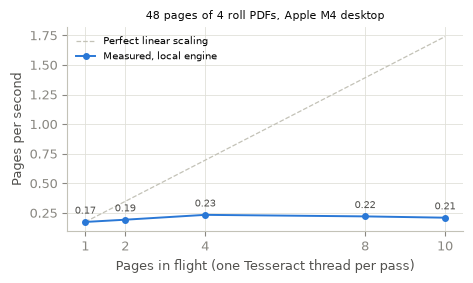

figures written: fig10_age_heaping.png, fig11_booth_distributions.png, fig12_household_size.png, fig13_scaling.png, fig1_roll_page_redacted.png, fig1b_cover_redacted.png, fig2_pipeline.png, fig3_accuracy_vs_baseline.png, fig4_flag_calibration.png, fig5_translit_ablation.png, fig6_part_size.png, fig7_completeness.png, fig8_jewar_flags.png, fig9_age_pyramids.png


In [14]:
# ---------- Fig 13: throughput vs pages in flight (CPU scaling benchmark) ----------
if "scaling" in ST:
    S = ST["scaling"]; xs = [r["conc"] for r in S["rows"]]; ys = [r["pages_per_s"] for r in S["rows"]]
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.plot(xs, [ys[0] * x for x in xs], ls="--", lw=0.9, color=AXIS, label="Perfect linear scaling")
    ax.plot(xs, ys, marker="o", ms=4, lw=1.4, color=BLUE, label="Measured, local engine")
    for x, y in zip(xs, ys): ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7, color=INK2)
    ax.set_xticks(xs); ax.set_xlabel("Pages in flight (one Tesseract thread per pass)"); ax.set_ylabel("Pages per second")
    ax.set_title(f"{S['pages']} pages of {S['pdfs']} roll PDFs, {S['machine']}", fontsize=8, color=INK); ax.legend(fontsize=7, loc="upper left")
    save("fig13_scaling.png")

json.dump(sizes, open(OUT + "sizes.json", "w"), indent=1)
print("figures written:", ", ".join(sorted(k for k in sizes)))

## 3. Under-18 check

`analysis/under18.cjs` counts, for every constituency, the rows printed with an age below 18 or above 120
and breaks them down by value. The result is in `data/gbn_stats.json` under `ageLt18`.

In [15]:
rows = []
for ac in ORDER:
    u = ACS[ac]["ageLt18"]
    rows.append({"AC": label(ac), "rows": ACS[ac]["rows"], "age < 18": u["total"], "% of rows": round(100 * u["total"] / ACS[ac]["rows"], 2),
                 "age 0 (not read)": u["zero"], "age 1-9": u["a1_9"], "age 10-17": u["a10_17"], "age 17": u["a17"], "age > 120": u["gt120"]})
df = pd.DataFrame(rows).set_index("AC"); df.loc["District"] = df.sum(numeric_only=True); df

,rows,age < 18,% of rows,age 0 (not read),age 1-9,age 10-17,age 17,age > 120
AC,,,,,,,,
61 Noida,589410,1056,0.18,929,126,1,0,7
62 Dadri,605115,902,0.15,822,80,0,0,5
63 Jewar,313297,131,0.04,115,16,0,0,0
District,1507822,2089,0.37,1866,222,1,0,12


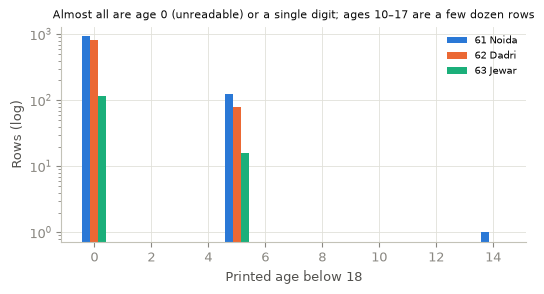

In [16]:
fig, ax = plt.subplots(figsize=(6, 2.8))
for ac in ORDER:
    h = ACS[ac]["ageLt18"].get("hist") or {"0": ACS[ac]["ageLt18"]["zero"], "5": ACS[ac]["ageLt18"]["a1_9"], "14": ACS[ac]["ageLt18"]["a10_17"]}; xs = sorted(int(k) for k in h)
    ax.bar([x + (ORDER.index(ac) - 1) * 0.28 for x in xs], [h[str(x)] for x in xs], 0.28, color=AC_COL[ac], label=label(ac))
ax.set_yscale("log"); ax.set_xlabel("Printed age below 18"); ax.set_ylabel("Rows (log)"); ax.legend(fontsize=7)
ax.set_title("Almost all are age 0 (unreadable) or a single digit; ages 10–17 are a few dozen rows", fontsize=8, color=INK); plt.show()

## 4. Duplicate EPICs, the DELETED stamp and post-draft deletions

The dashboard holds no row with status `deleted` for any of the three constituencies, yet the roll prints
the cards of electors removed after the draft with a diagonal **DELETED** watermark and a reason letter
(S shifted, E expired, R duplicate) in the serial box. The OCR pipeline missed the stamp (the overprint
garbled the name and blanked the gender instead), so every such card was written as an existing elector,
and the "duplicate EPIC" groups were, almost without exception, one stamped old card plus one fresh
addition of the same person in another part.

`analysis/deleted_stats.cjs` measured the overlap; `analysis/stamp_scan.py` then scanned every card page
of the three rolls with a pixel-level stamp detector (grey ink sheared along the 30° direction of the
stamp), calibrated on 35 hand-checked cards.

In [17]:
ds = json.load(open("analysis/deleted_stats.json"))
rows = []
for ac in ORDER:
    d = ds[ac]; g = d["dup"]
    rows.append({"AC": label(ac), "status counts": {s: n for s, r, n in d["status"]}, "gender blank": d["blankGender"],
                 "dup-EPIC groups": g["groups"], "cross-part": g["crossPart"], "with an added row": g["withAdded"],
                 "with a blank-gender row": g["withBlank"], "same age": g["sameAge"], "with a deleted row": g["withDel"]})
pd.DataFrame(rows).set_index("AC")

,status counts,gender blank,dup-EPIC groups,cross-part,with an added row,with a blank-gender row,same age,with a deleted row
AC,,,,,,,,
61 Noida,"{'modified': 4236, 'added': 29736, 'existing':...",8246,2201,2201,2200,2163,1907,0
62 Dadri,"{'existing': 556006, 'modified': 4623, 'added'...",5999,2533,2533,2532,2479,2133,0
63 Jewar,"{'modified': 1748, 'existing': 291581, 'added'...",1069,234,234,228,227,191,0


In [18]:
# Stamp-scan results (one JSON line per card: page, idx, band, residBand, residFrac, black), when present.
import glob
SCAN = "analysis/stampscan"
BAND_MIN, RESID_MIN = 0.15, 0.04
summary = {}
for ac, folder in (("61", "61-Noida"), ("62", "62-Dadri"), ("63", "63-Jewar")):
    files = glob.glob(f"{SCAN}/{folder}/*.jsonl")
    if not files: continue
    n = stamped = 0
    for f in files:
        for line in open(f):
            x = json.loads(line)
            if "band" not in x or not (0.004 < x["black"] < 0.08) or x["page"] <= 2: continue
            n += 1; stamped += (x["band"] >= BAND_MIN and x["residBand"] >= RESID_MIN)
    summary[ac] = {"parts scanned": len(files), "cards": n, "stamped": stamped, "% stamped": round(100 * stamped / max(n, 1), 2)}
pd.DataFrame(summary).T if summary else "stamp-scan outputs not present (run analysis/stamp_scan.py where the PDFs are)"

,parts scanned,cards,stamped,% stamped
61,811.0,608288.0,6342.0,1.04
62,794.0,624486.0,4666.0,0.75
63,419.0,321158.0,932.0,0.29


,parts scanned,cards,stamped,% stamped,"re-added elsewhere, same age",gender unreadable by OCR,dup-EPIC groups with a stamped member,median age of stamped
AC,,,,,,,,
61 Noida,811,608288,6342,1.043,1690,5720,1957,44
62 Dadri,794,624486,4666,0.747,1862,3991,2193,43
63 Jewar,419,321158,932,0.290,171,862,203,41


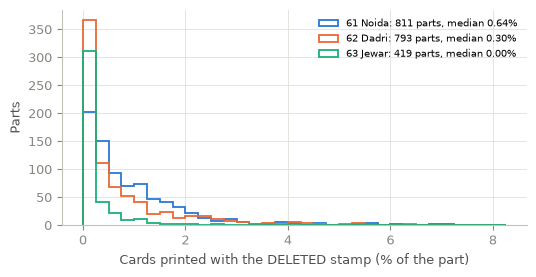

In [19]:
# Aggregates written by analysis/stamp_join.cjs (scan joined to the dashboard rows by part, page and position)
if "stamp" in ST:
    rows = []
    for ac in ORDER:
        if ac not in ST["stamp"]: continue
        s = ST["stamp"][ac]
        rows.append({"AC": label(ac), "parts scanned": s["partsScanned"], "cards": s["cards"], "stamped": s["stamped"], "% stamped": s["stampedPct"],
                     "re-added elsewhere, same age": s["readdedSameAge"], "gender unreadable by OCR": s["blankGender"],
                     "dup-EPIC groups with a stamped member": s["dupGroupsWithStampedMember"], "median age of stamped": s["medianAge"]})
    display(pd.DataFrame(rows).set_index("AC"))
    fig, ax = plt.subplots(figsize=(6, 2.8))
    for ac in ORDER:
        if ac not in ST["stamp"]: continue
        pp = ST["stamp"][ac]["perPart"]; v = [100 * p["stamped"] / p["cards"] for p in pp if p["cards"] > 100]
        ax.hist(v, bins=np.arange(0, 8.5, 0.25), histtype="step", lw=1.3, color=AC_COL[ac], label=f"{label(ac)}: {len(v)} parts, median {np.median(v):.2f}%")
    ax.set_xlabel("Cards printed with the DELETED stamp (% of the part)"); ax.set_ylabel("Parts"); ax.legend(fontsize=7); plt.show()
else:
    print("no stamp aggregates yet")

## 5. CPU scaling benchmark (Table 4b)

`analysis/bench/run_bench.sh` ran the same 48 pages at 1, 2, 4, 8 and 10 pages in flight on an idle Apple M4.

In [20]:
S = ST["scaling"]; df = pd.DataFrame(S["rows"])
df["cores busy"] = ((df.user_s + df.sys_s) / df.wall_s).round(1); df["CPU-s per page"] = ((df.user_s + df.sys_s) / df.pages).round(1)
df[["conc", "wall_s", "pages_per_s", "cores busy", "CPU-s per page", "max_rss_mb"]].set_index("conc")

,wall_s,pages_per_s,cores busy,CPU-s per page,max_rss_mb
conc,,,,,
1,276.6,0.174,2.1,11.9,271
2,249.6,0.193,3.9,20.5,325
4,205.4,0.234,6.4,27.4,404
8,218.0,0.221,6.6,30.1,497
10,229.0,0.210,6.4,30.5,607


## 6. Rebuild the paper

```
NODE_PATH=<folder with the docx module> node build_paper.cjs
```
writes `Making_the_Invisible_Roll_Visible.docx` from the same `data/gbn_stats.json` and the figures above.